In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from IPython.display import HTML, Audio

In [2]:
# filename = librosa.ex("trumpet")
# y, sr = librosa.load(filename)
y, sr = librosa.loadx("trumpet")
HTML(librosa.util.example_info("trumpet"))
Audio(y, rate=sr)

solo trumpet 06
Attribution: Mihai Sorohan
License:     CC-BY-4.0
Source:      https://freesound.org/s/77711/

Part of "Jazz Trumpet Loops Pack in F 90 bpm" by Mihai Sorohan
All parts in this pack are in F, mostly Blues and Dorian scale and all are in stereo acidized .wav format, 16 bit, 44.1 khz sample rate, 90 bpm.

Gear used:
- trumpet Bb Amati ATR213
- microphone Oktava MK 319
- preamp Art Tube MP Project Series
- soundcard M-Audio Delta Audiophile 192


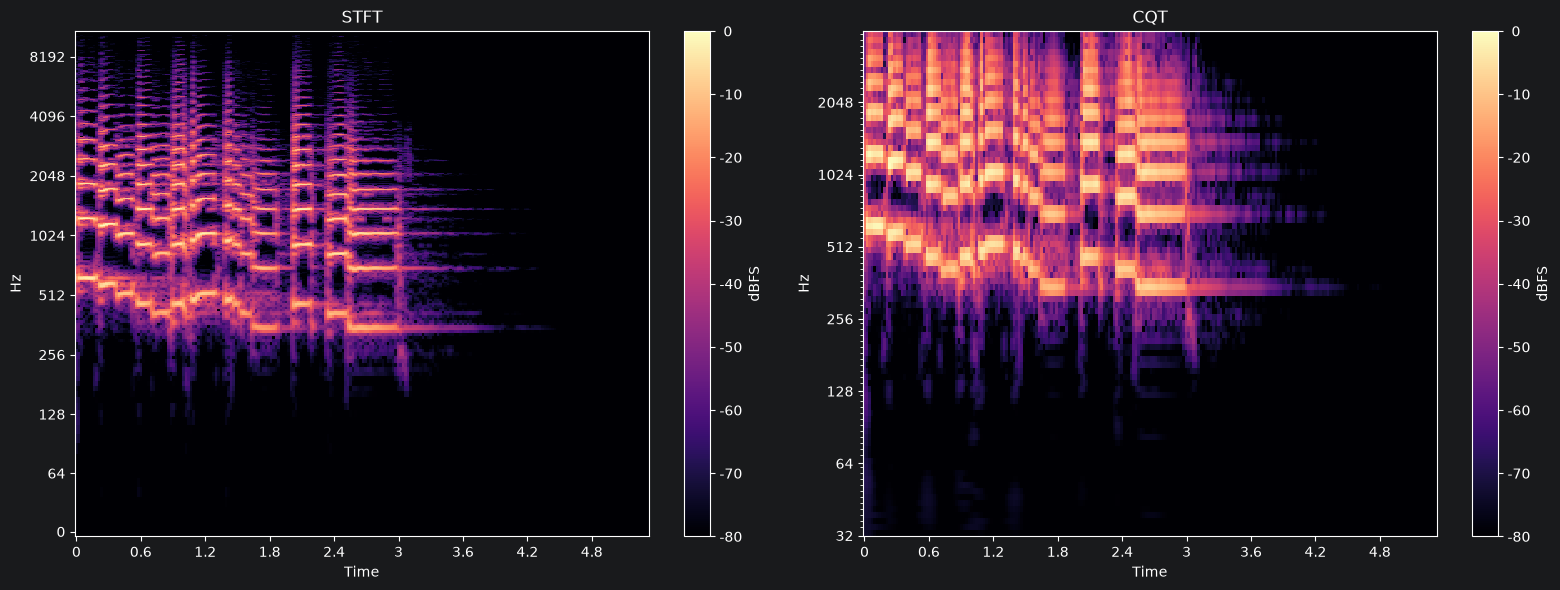

In [3]:
S = np.abs(librosa.stft(y))
C = librosa.cqt(y=y, sr=sr)
fig, ax = plt.subplots(1,2, figsize=(16,6))
img1 = librosa.display.specshow(S, vscale="dBFS", x_axis="time", y_axis="log", ax=ax[0])
img2 = librosa.display.specshow(C, vscale="dBFS", x_axis="time", y_axis="cqt_hz", ax=ax[1])
librosa.display.colorbar_db(img1, label="dBFS")
librosa.display.colorbar_db(img2, label="dBFS")
ax[0].set_title("STFT")
ax[1].set_title("CQT")
plt.tight_layout()
plt.show()

The image above should look somewhat similar to the visualization of the STFT, with two exceptions:

- The frequency resolution is lower: we have only 84 frequencies now instead of 1025.
- The frequency range is lower: the plot stops at about 4 KHz instead of 11 KHz in the STFT.

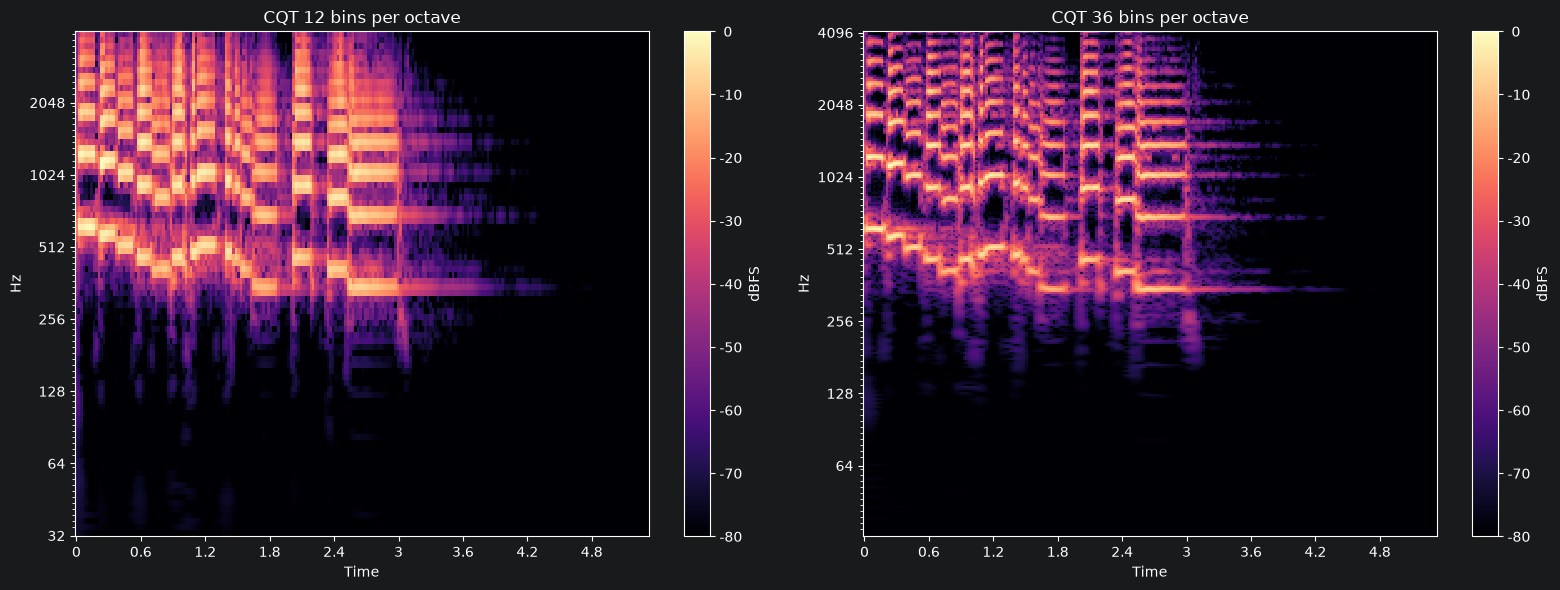

In [4]:
C12 = librosa.cqt(y=y, sr=sr)
C36 = librosa.cqt(y=y, sr=sr, bins_per_octave=12*3, n_bins=12*3*7)
fig, ax = plt.subplots(1,2, figsize=(16,6))
img1 = librosa.display.specshow(C12, vscale="dBFS", x_axis="time", y_axis="cqt_hz", ax=ax[0])
img2 = librosa.display.specshow(C36, vscale="dBFS", x_axis="time", y_axis="cqt_hz", bins_per_octave=12*3, ax=ax[1])
librosa.display.colorbar_db(img1, label="dBFS")
librosa.display.colorbar_db(img2, label="dBFS")
ax[0].set_title("CQT 12 bins per octave")
ax[1].set_title("CQT 36 bins per octave")
plt.tight_layout()
plt.show()

In [5]:
print(f"STFT: {S.shape} | CGT12: {C12.shape} | CQT36: {C36.shape}")

STFT: (1025, 230) | CGT12: (84, 230) | CQT36: (252, 230)


In [6]:
y, sr = librosa.loadx("sweetwaltz", duration=15)
HTML(librosa.util.example_info("sweetwaltz"))
Audio(y, rate=sr)

Sweet Waltz
Attribution: setuniman
License:     CC-BY-NC-4.0
Source:      https://freesound.org/people/Setuniman/sounds/147793/

Steady change between two naive major phrases beginning with wooden timbre is gradually layered by flute and organ colours. Made with synths.


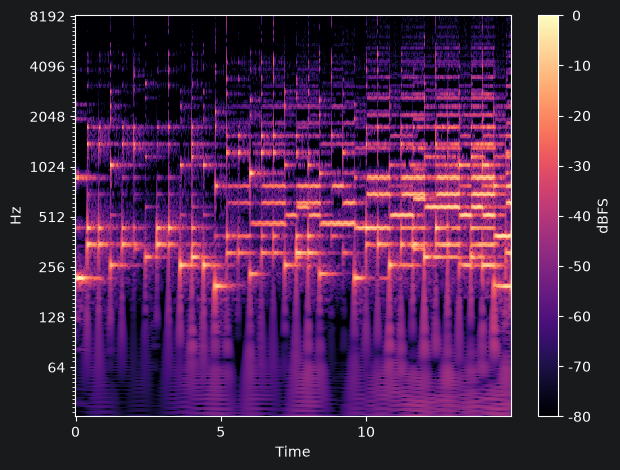

In [7]:
# CQT of Sweetwaltz
C = librosa.cqt(y, sr=sr, bins_per_octave=12*3, n_bins=12*3*8)
fig, ax = plt.subplots()
img = librosa.display.specshow(C, vscale="dBFS", x_axis="time", y_axis="cqt_hz", bins_per_octave=12*3, ax=ax)
librosa.display.colorbar_db(img, label="dBFS")
plt.tight_layout()
plt.show()

# Chroma

/var/folders/nz/tc8kblqd2t7_dy6zspp6kx580000gn/T/ipykernel_25199/2483252502.py:7: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(imgchroma, ax=ax[1], aspect=20/3)  # aspect compensates for the 3:1 height ratio of these plots


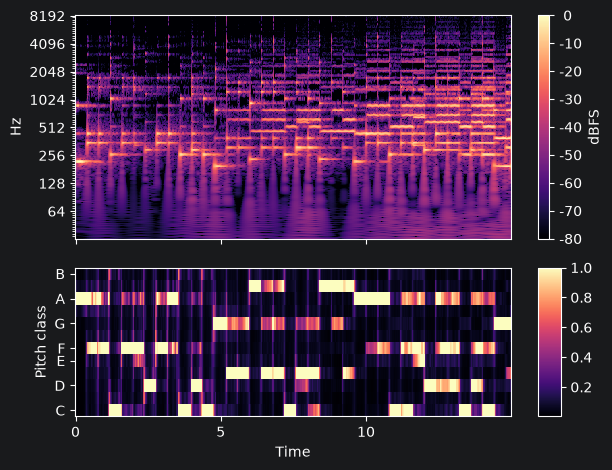

In [8]:
chroma = librosa.feature.chroma_cqt(y=y, sr=sr)
fix, ax = plt.subplots(nrows=2, sharex=True, height_ratios=(3,2))
imgcqt = librosa.display.specshow(C, vscale="dBFS", x_axis="time", y_axis="cqt_hz", bins_per_octave=12*3, ax=ax[0])
librosa.display.colorbar_db(imgcqt, label="dBFS")
ax[0].label_outer()    # only show x-axis labels on the bottom plot
imgchroma = librosa.display.specshow(chroma, x_axis="time", y_axis="chroma", ax=ax[1])
fig.colorbar(imgchroma, ax=ax[1], aspect=20/3)  # aspect compensates for the 3:1 height ratio of these plots
plt.tight_layout()
plt.show()

# Viterbi Example

In [20]:
# Create templates for major, minor, and no-chord qualities
maj_template = np.array([1,0,0, 0,1,0, 0,1,0, 0,0,0])
min_template = np.array([1,0,0, 1,0,0, 0,1,0, 0,0,0])
N_template   = np.array([1,1,1, 1,1,1, 1,1,1, 1,1,1.]) / 4.

# Generate the weighting matrix that maps chroma to labels
weights = np.zeros((25, 12), dtype=float)
labels = ['C:maj', 'C#:maj', 'D:maj', 'D#:maj', 'E:maj', 'F:maj',
          'F#:maj', 'G:maj', 'G#:maj', 'A:maj', 'A#:maj', 'B:maj',
          'C:min', 'C#:min', 'D:min', 'D#:min', 'E:min', 'F:min',
          'F#:min', 'G:min', 'G#:min', 'A:min', 'A#:min', 'B:min',
          'N']
for c in range(12):
    weights[c, :] = np.roll(maj_template, c) # c:maj
    weights[c + 12, :] = np.roll(min_template, c)  # c:min
weights[-1] = N_template  # the last row is the no-chord class

# # Make a self-loop transition matrix over 25 states
trans = librosa.sequence.transition_loop(25, 0.9)


In [39]:
# Load in audio and make features
y, sr = librosa.loadx("nutcracker", duration=15)

# Suppress percussive elements
y_harm = librosa.effects.harmonic(y, margin=4.0)


In [35]:
Audio(y, rate=sr)

In [38]:
Audio(y_harm, rate=sr)

In [65]:
chroma_harm.shape

(12, 646)

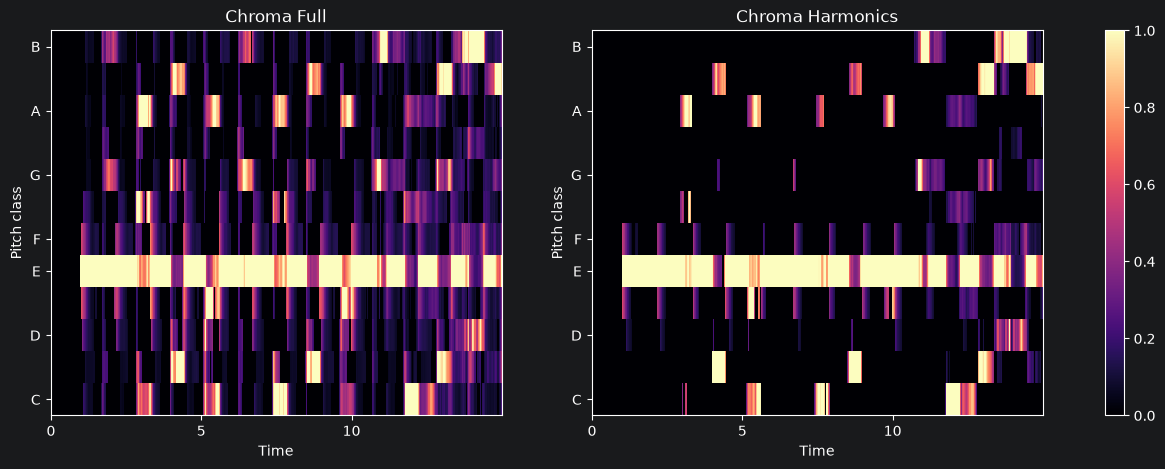

In [50]:
chroma_full = librosa.feature.chroma_cqt(y=y, sr=sr, threshold=0.25)
chroma_harm = librosa.feature.chroma_cqt(y=y_harm, sr=sr, threshold=0.25)
fig, ax = plt.subplots(1, 2, figsize=(16,5))
imgchroma = librosa.display.specshow(chroma_full, x_axis="time", y_axis="chroma", ax=ax[0])
imgchroma = librosa.display.specshow(chroma_harm, x_axis="time", y_axis="chroma", ax=ax[1])
fig.colorbar(imgchroma, ax=ax)
ax[0].set_title("Chroma Full")
ax[1].set_title("Chroma Harmonics")
plt.show()


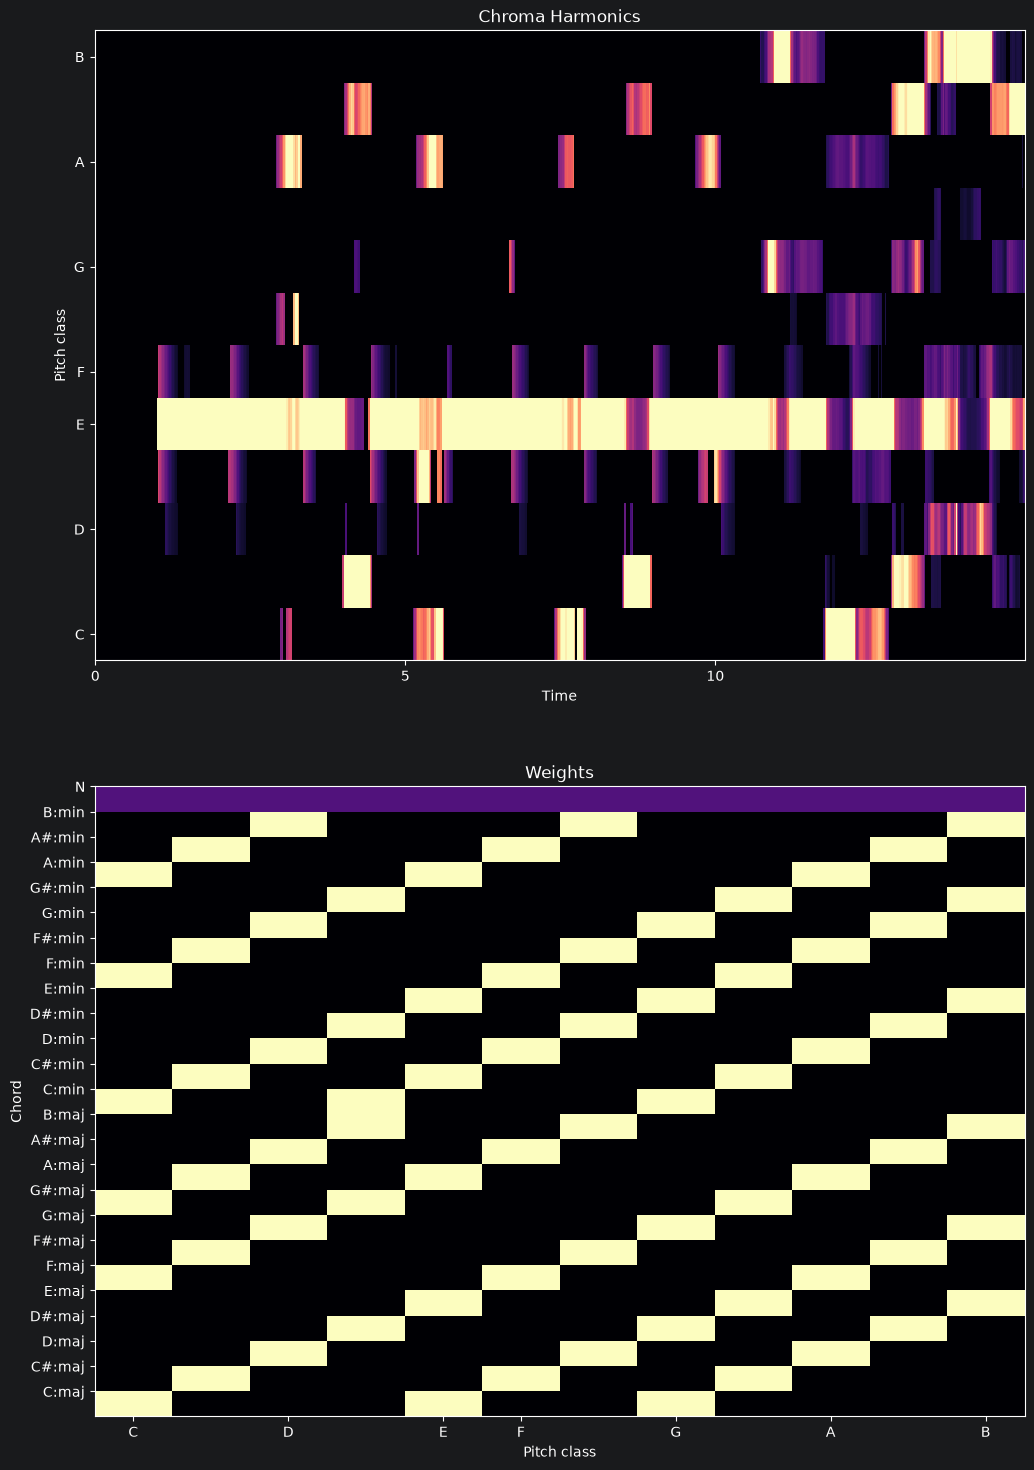

In [101]:
fix, ax = plt.subplots(nrows=2, figsize=(12,18))
librosa.display.specshow(chroma_harm, x_axis="time", y_axis="chroma", ax=ax[0])
librosa.display.specshow(weights, x_axis="chroma", ax=ax[1], auto_aspect=False)
ax[0].set_title("Chroma Harmonics")
ax[1].set_title("Weights")
ax[1].set(yticks=np.arange(25) +0.5, yticklabels=labels, ylabel="Chord")
plt.show()

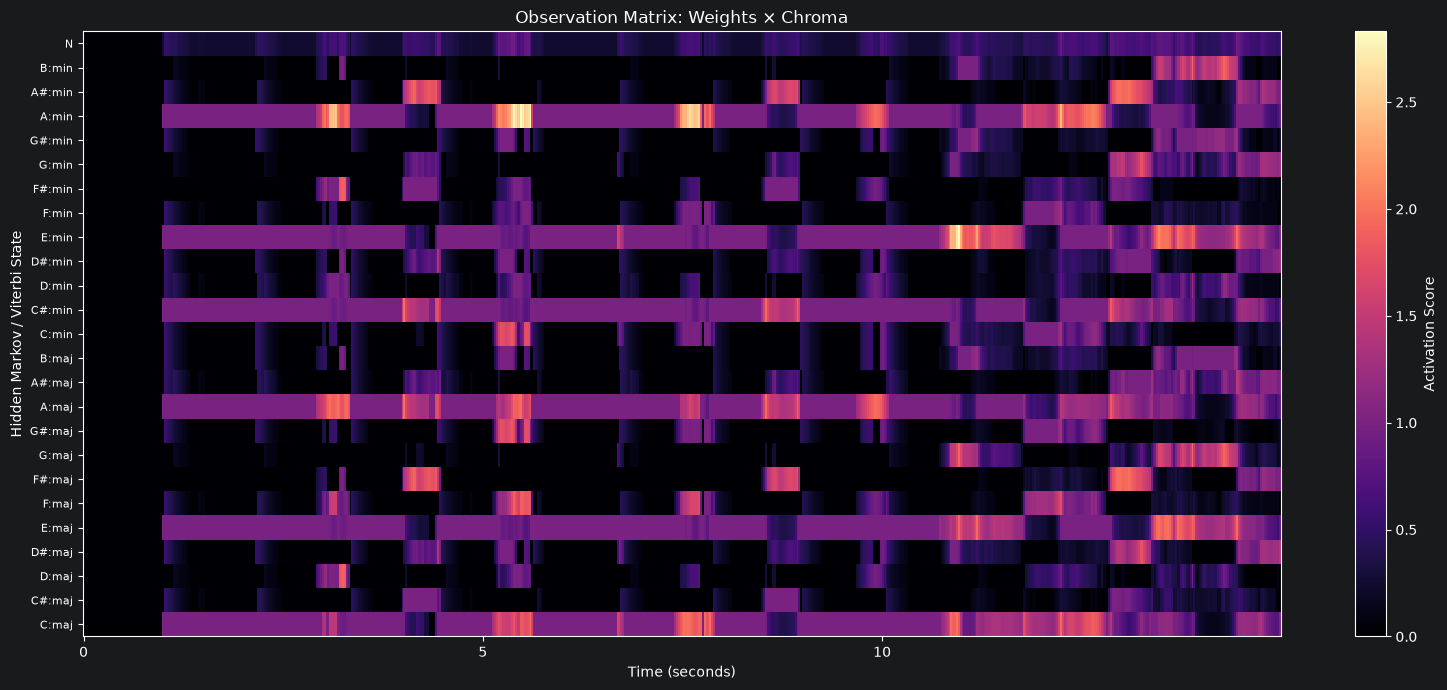

In [102]:
# 25 chord states: 12 Major, 12 Minor, 1 No-chord ('N')
chord_labels = [
    'C:maj',
    'C#:maj',
    'D:maj',
    'D#:maj',
    'E:maj',
    'F:maj',
    'F#:maj',
    'G:maj',
    'G#:maj',
    'A:maj',
    'A#:maj',
    'B:maj',
    'C:min',
    'C#:min',
    'D:min',
    'D#:min',
    'E:min',
    'F:min',
    'F#:min',
    'G:min',
    'G#:min',
    'A:min',
    'A#:min',
    'B:min',
    'N',
]

fig, ax = plt.subplots(1, 1, figsize=(16, 7))
imgweights = librosa.display.specshow(weights.dot(chroma_harm), sr=sr, x_axis="time", y_axis=None, cmap="magma", ax=ax, auto_aspect=False)
# Configure 25 discrete Y-axis labels
ax.set_yticks(np.arange(len(chord_labels)))
ax.set_yticklabels(chord_labels, fontsize=8)
ax.set_ylabel('Hidden Markov / Viterbi State')
ax.set_xlabel('Time (seconds)')
ax.set_title('Observation Matrix: Weights × Chroma')

fig.colorbar(imgweights, ax=ax, label='Activation Score')
plt.tight_layout()
plt.show()

In [103]:
# Map chroma (observations) to class (state) likelihoods -> Posterior
scores = weights.dot(chroma)
posteriors = np.exp(scores)
# final posterior probabilities matrix
posteriors /= posteriors.sum(axis=0, keepdims=True)

In [104]:
# Compute independent frame-wise estimates
chords_ind = np.argmax(posteriors, axis=0)

# And viterbi estimates
chords_vit = librosa.sequence.viterbi_discriminative(posteriors, trans)

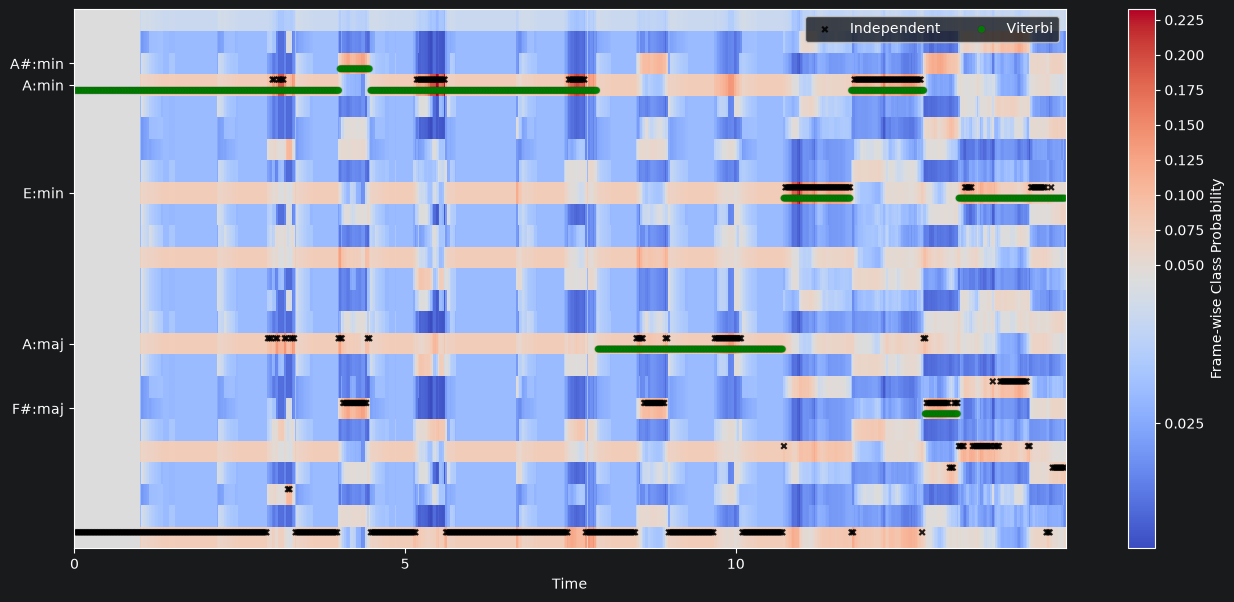

In [106]:
# Plot the results
fig, ax = plt.subplots(figsize=(16,7))
img = librosa.display.specshow(posteriors, x_axis="time", ax=ax, div_thresh=1./25)
hl = librosa.display.highlight(ax=ax, alpha=0.1)
fig.colorbar(img, ax=ax, label='Frame-wise Class Probability')
times = librosa.times_like(chords_vit)
ax.scatter(times, chords_ind + 0.25, alpha=0.85, marker='x', color='k',
           s=15, label='Independent', path_effects=hl)
ax.scatter(times, chords_vit - 0.25, alpha=0.85, marker='o', color='g',
           s=15, label='Viterbi', path_effects=hl)
ax.set(yticks=np.unique(chords_vit),
       yticklabels=[labels[i] for i in np.unique(chords_vit)])
ax.legend(loc='upper right', ncols=2)
plt.show()

